In [1]:
import scipy.io
import numpy as np

data=scipy.io.loadmat("data/bearing.mat")
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'ADC'])


In [2]:
for key in data:
    if not key.startswith("__"):
        print(key,type(data[key]),data[key].shape)


ADC <class 'numpy.ndarray'> (4, 2775731)


In [3]:
ADC=data['ADC']
print("Row 1:",ADC[0,0:10])
print("Row 2:",ADC[1,0:10])
print("Row 3:",ADC[2,0:10])
print("Row 4:",ADC[3,0:10])

Row 1: [6106.417785   6106.417985   6106.41818499 6106.41838499 6106.41858499
 6106.41878499 6106.41898498 6106.41918498 6106.41938498 6106.41958497]
Row 2: [0.04552032 0.08053596 0.07353283 0.07353283 0.06302814 0.07003127
 0.06302814 0.05602501 0.06302814 0.07353283]
Row 3: [-0.00551907  0.02023658  0.0165572   0.0165572   0.02023658  0.00919845
  0.00919845  0.00183969  0.00183969  0.00551907]
Row 4: [0.13207262 0.14544706 0.13875984 0.14544706 0.13875984 0.13875984
 0.13875984 0.13541623 0.128729   0.13875984]


In [4]:
ADC

array([[ 6.10641778e+03,  6.10641798e+03,  6.10641818e+03, ...,
         6.66154628e+03,  6.66154648e+03,  6.66154668e+03],
       [ 4.55203230e-02,  8.05359561e-02,  7.35328295e-02, ...,
        -1.40075984e-02, -1.75094980e-02, -2.45132973e-02],
       [-5.51906730e-03,  2.02365801e-02,  1.65572019e-02, ...,
         2.20783884e-02,  0.00000000e+00, -3.31175826e-02],
       [ 1.32072615e-01,  1.45447057e-01,  1.38759836e-01, ...,
        -1.33757261e-01, -1.43789055e-01, -1.47132987e-01]],
      shape=(4, 2775731))

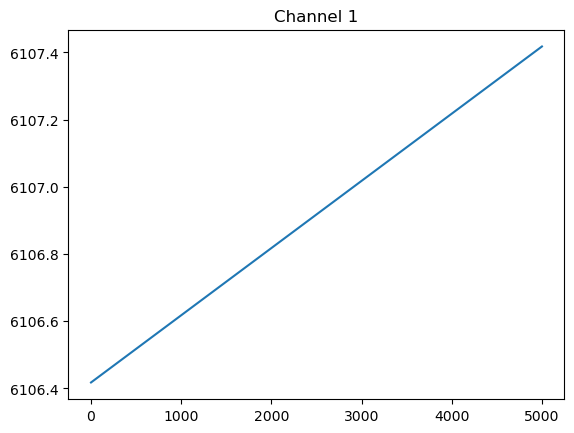

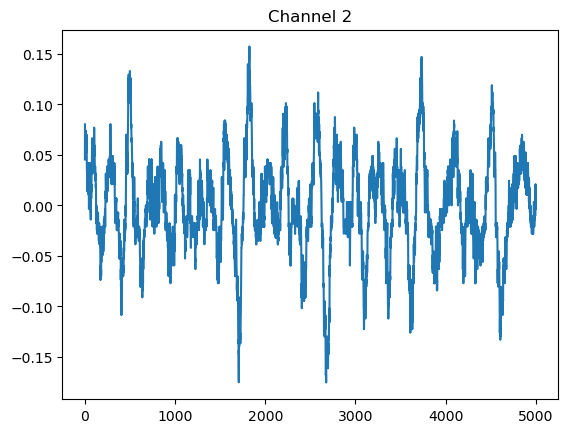

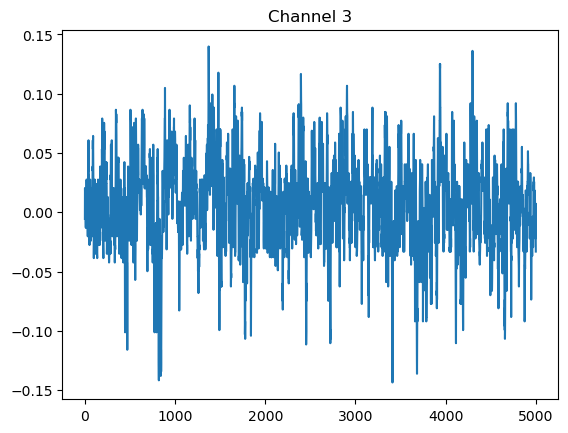

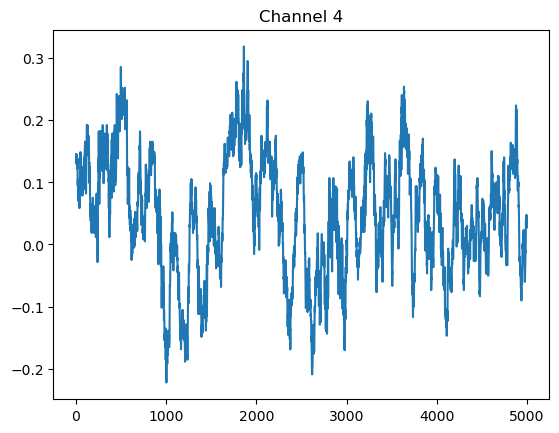

In [5]:
import matplotlib.pyplot as plt

for i in range(4):
    plt.plot(ADC[i,:5000])
    plt.title(f"Channel {i+1}")
    plt.show()

## we can say that the 1st row is time

In [6]:
#selected second row as vibration
vibration = ADC[1, :] 
time=ADC[0,:]

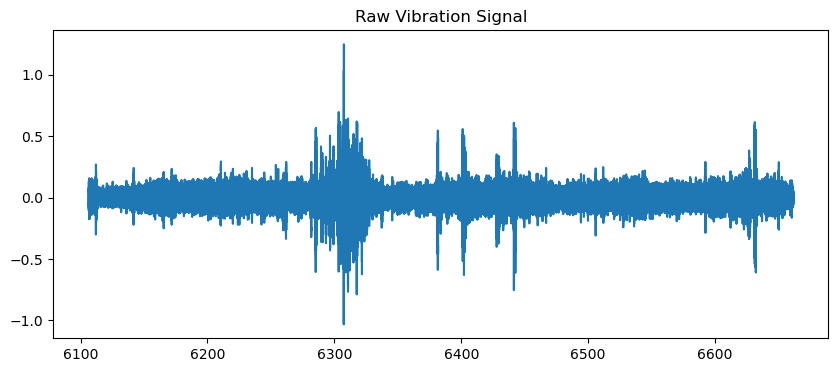

In [7]:
plt.figure(figsize=(10,4))
plt.plot(time,vibration)   
plt.title("Raw Vibration Signal")
plt.show()


In [8]:
Fs = 1 / np.mean(np.diff(time))
print("Sampling Frequency:",Fs,"Hz")

Sampling Frequency: 5000.154108334961 Hz


In [9]:
window_time=10   
window_size=int(Fs*window_time)
step = window_size//2  
print("Window size (samples):",window_size)


Window size (samples): 50001


In [10]:
time_final=[]
for i in range(0,len(vibration)-window_size,step):
    t=time[i+window_time//2]
    time_final.append(t)

time_final=np.array(time_final)

## 1] RMS

RMS gives the effective vibration level (energy) of the bearing.“How strong is the vibration in this time window?”RMS increases steadily as defect grows

In [11]:
rms=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    rms_val=np.sqrt(np.mean(segment**2))
    rms.append(rms_val)

rms=np.array(rms)


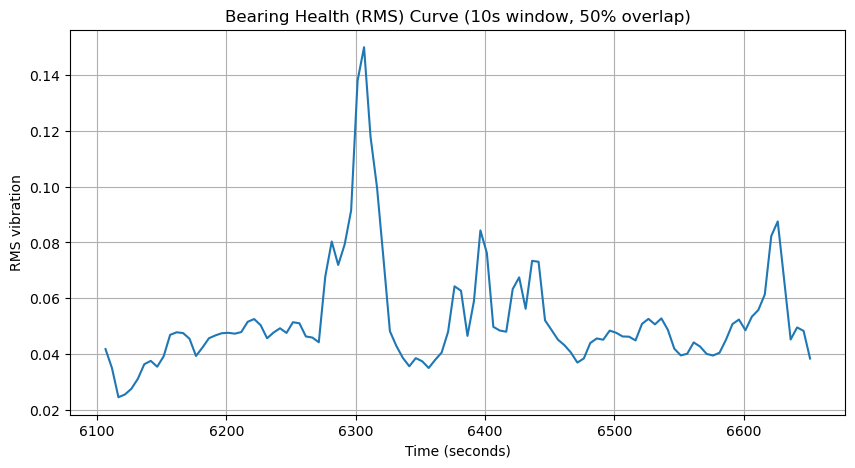

In [12]:
plt.figure(figsize=(10,5))
plt.plot(time_final,rms)
plt.xlabel("Time (seconds)")
plt.ylabel("RMS vibration")
plt.title("Bearing Health (RMS) Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()


Sudden peaks indicate impact events such as crack initiation. The bearing in this dataset shows early to mid-stage fault behavior.

## 2] Mean

Mean gives the average value of the vibration signal in a time window.It is mainly used to detect signal bias or offset rather than bearing damage.

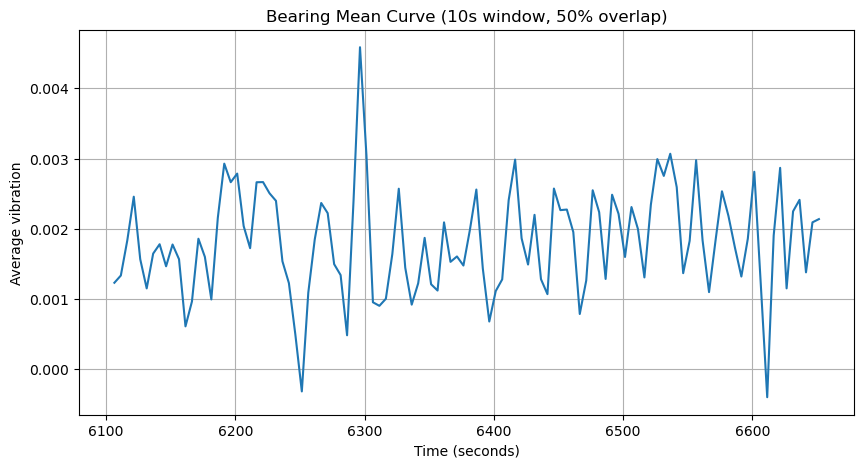

In [13]:
mean=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    mean_val=np.mean(segment)
    mean.append(mean_val)
mean=np.array(mean)


plt.figure(figsize=(10,5))
plt.plot(time_final,mean)
plt.xlabel("Time (seconds)")
plt.ylabel("Average vibration")
plt.title("Bearing Mean Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

Vibration signal is well-centered around zero.No major DC offset. This confirms good sensor quality.

## 3]Standard deviation

Standard deviation tells how much the vibration values spread around the mean. And increases as bearing vibration becomes more irregular due to defects.

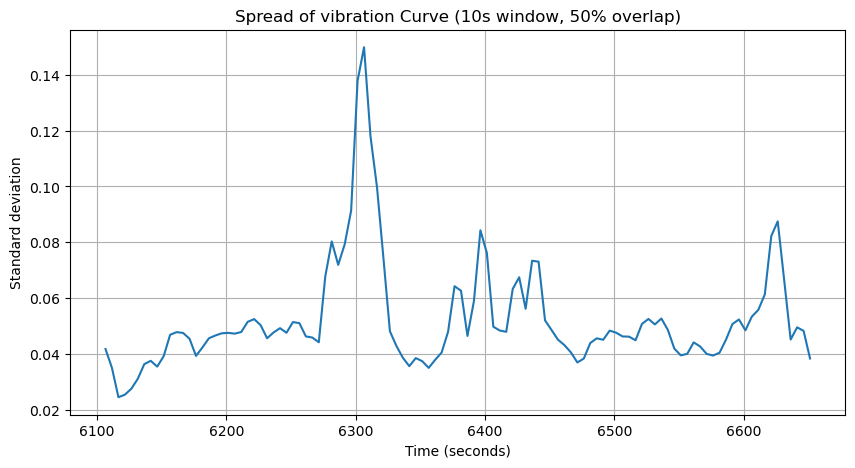

In [14]:
std=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    std_val=np.std(segment)
    std.append(std_val)
std=np.array(std)


plt.figure(figsize=(10,5))
plt.plot(time_final,std)
plt.xlabel("Time (seconds)")
plt.ylabel("Standard deviation")
plt.title("Spread of vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 4]Variance

Variance measures how much the vibration values vary around the mean. How unstable is the vibration signal?

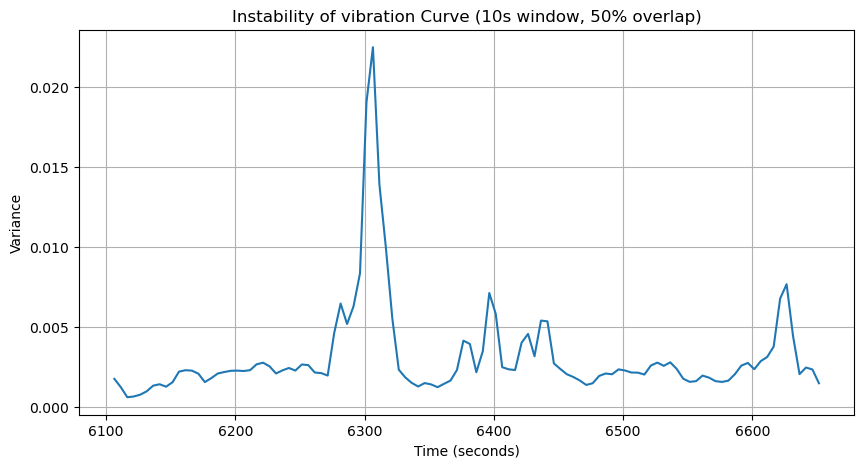

In [15]:
var=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    var_val=np.var(segment)
    var.append(var_val)
var=np.array(var)


plt.figure(figsize=(10,5))
plt.plot(time_final,var)
plt.xlabel("Time (seconds)")
plt.ylabel("Variance")
plt.title("Instability of vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

In [16]:
from scipy.stats import skew, kurtosis

skew_l=[]
kurtosis_l=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    skew_val=skew(segment)
    skew_l.append(skew_val)
    kurtosis_val=kurtosis(segment)
    kurtosis_l.append(kurtosis_val)
    
skew_l=np.array(skew_l)
kurtosis_l=np.array(kurtosis_l)


## 5]Skewness

Skewness measures the asymmetry of the vibration signal distribution. Is the vibration more biased toward positive or negative peaks?

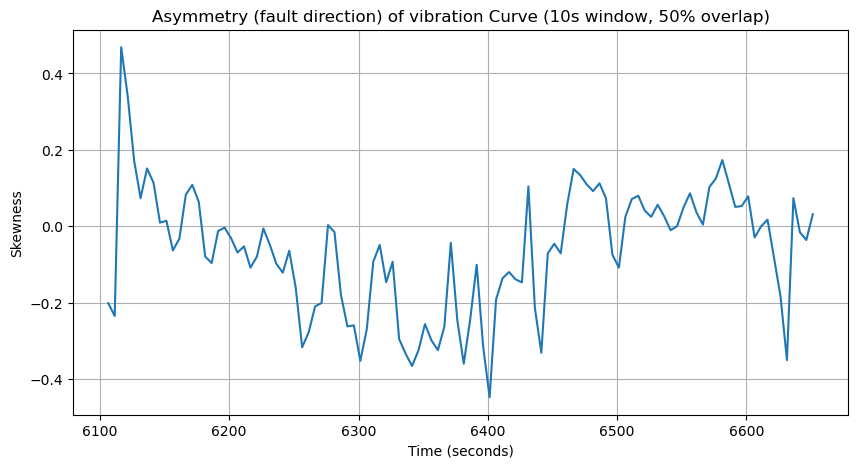

In [17]:
plt.figure(figsize=(10,5))
plt.plot(time_final,skew_l)
plt.xlabel("Time (seconds)")
plt.ylabel("Skewness")
plt.title("Asymmetry (fault direction) of vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 6]Kurtosis

Kurtosis measures how spiky or impulsive the vibration signal is. How many sharp impacts are present in the vibration?.It is highly sensitive to bearing cracks and impact-type faults.

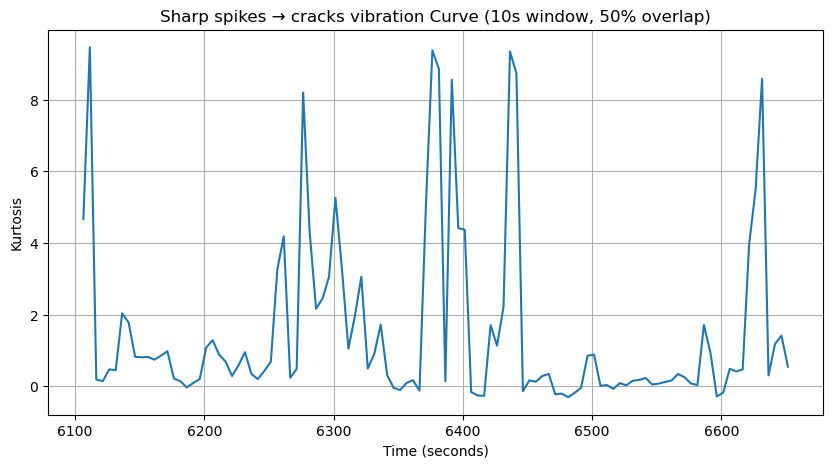

In [18]:
plt.figure(figsize=(10,5))
plt.plot(time_final,kurtosis_l)
plt.xlabel("Time (seconds)")
plt.ylabel("Kurtosis")
plt.title("Sharp spikes → cracks vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 7]Peak

Peak value represents the maximum vibration and is useful for detecting sudden shocks.

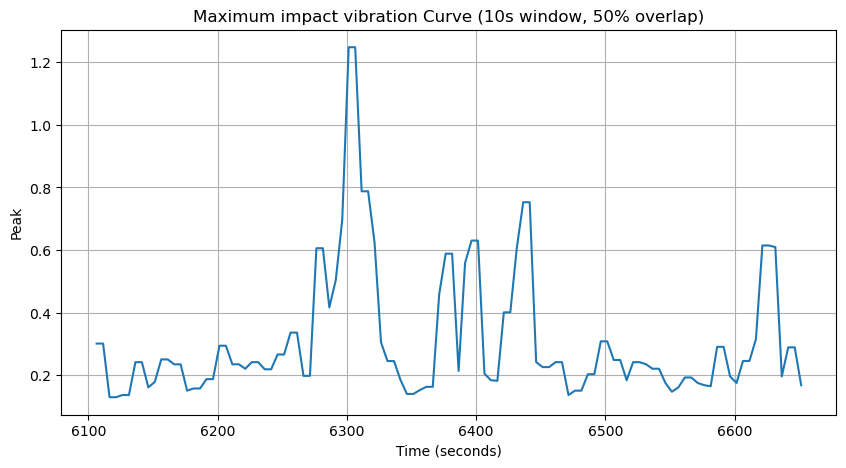

In [19]:
peak=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    peak_val=np.max(np.abs(segment))
    peak.append(peak_val)
peak=np.array(peak)


plt.figure(figsize=(10,5))
plt.plot(time_final,peak)
plt.xlabel("Time (seconds)")
plt.ylabel("Peak")
plt.title("Maximum impact vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 8]Peak to Peak

Peak-to-Peak value gives the total vibration swing between the maximum positive and maximum negative.So it measures the full range of vibration motion.

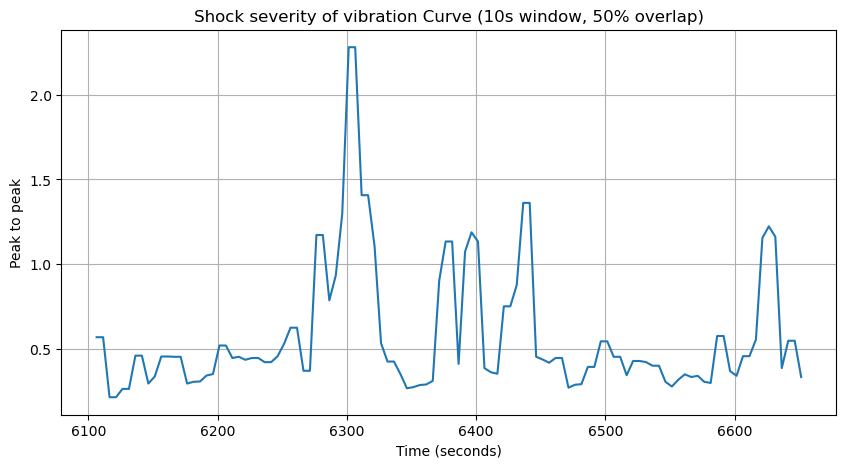

In [20]:
ptp=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    ptp_val=np.ptp(segment)
    ptp.append(ptp_val)
ptp=np.array(ptp)


plt.figure(figsize=(10,5))
plt.plot(time_final,ptp)
plt.xlabel("Time (seconds)")
plt.ylabel("Peak to peak")
plt.title("Shock severity of vibration Curve (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 9]Crest Factor (Peak/RMS)

Crest Factor measures how impulsive the vibration signal is.How large are the peaks compared to the overall vibration energy?

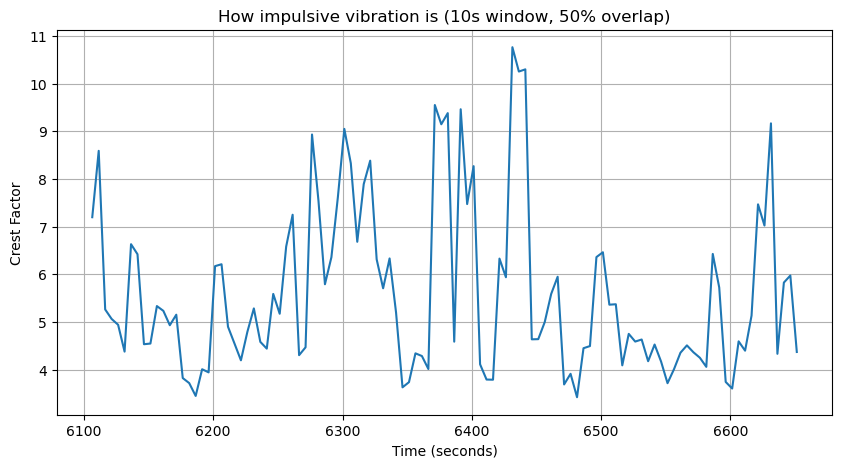

In [21]:
crest=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    crest_val=(np.max(np.abs(segment)))/np.sqrt(np.mean(segment**2))
    crest.append(crest_val)
crest=np.array(crest)


plt.figure(figsize=(10,5))
plt.plot(time_final,crest)
plt.xlabel("Time (seconds)")
plt.ylabel("Crest Factor")
plt.title("How impulsive vibration is (10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 10]Mean Absolute Value

MAV gives the average magnitude of vibration, ignoring direction (sign).

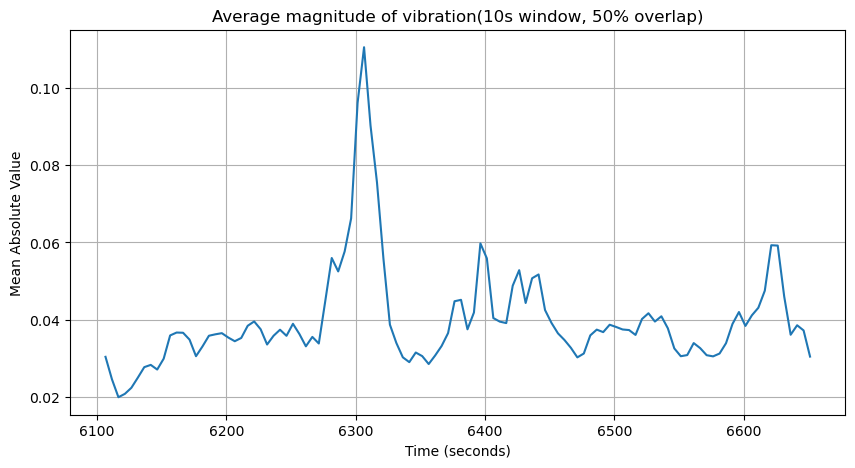

In [22]:
mav=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    mav_val=np.mean(np.abs(segment))
    mav.append(mav_val)
mav=np.array(mav)


plt.figure(figsize=(10,5))
plt.plot(time_final,mav)
plt.xlabel("Time (seconds)")
plt.ylabel("Mean Absolute Value")
plt.title("Average magnitude of vibration(10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 11]Shape Factor (RMS/MAV)

Shape Factor describes the shape of the vibration waveform.

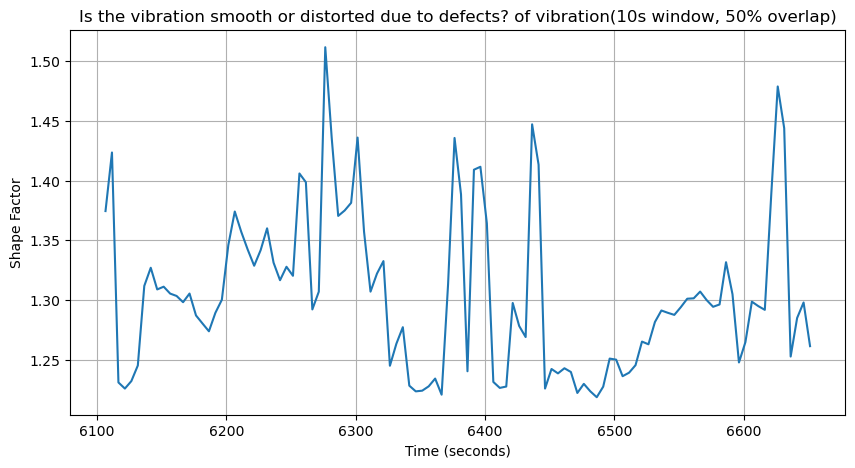

In [23]:
sf=[]

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    sf_val=np.sqrt(np.mean(segment**2))/np.mean(np.abs(segment))
    sf.append(sf_val)
sf=np.array(sf)


plt.figure(figsize=(10,5))
plt.plot(time_final,sf)
plt.xlabel("Time (seconds)")
plt.ylabel("Shape Factor")
plt.title("Is the vibration smooth or distorted due to defects? of vibration(10s window, 50% overlap)")
plt.grid(True)
plt.show()

## 12]Clearance Factor

Clearance factor is the ratio of peak vibration to the square of the mean square-root amplitude and is highly sensitive to bearing looseness and clearance-related faults.

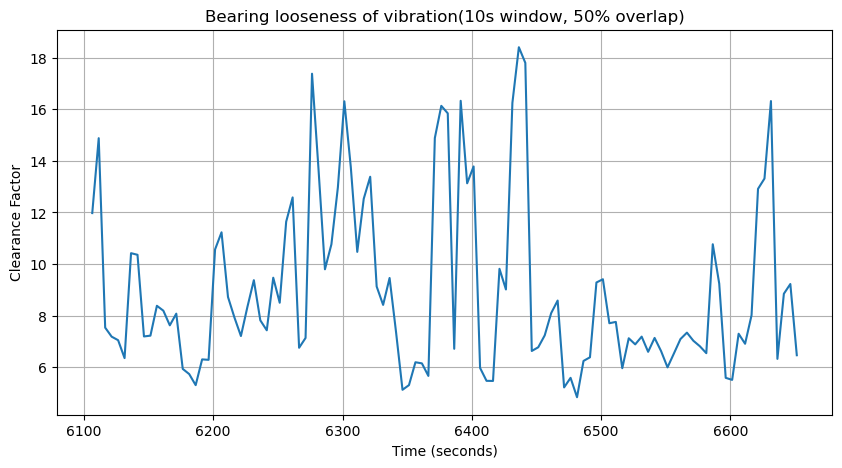

In [24]:
cf=[]
count=0

for i in range(0,len(vibration)-window_size,step):
    segment=vibration[i:i+window_size]
    cf_val=np.max(np.abs(segment))/(np.mean(np.sqrt(np.abs(segment)))**2)
    cf.append(cf_val)
cf=np.array(cf)


plt.figure(figsize=(10,5))
plt.plot(time_final,cf)
plt.xlabel("Time (seconds)")
plt.ylabel("Clearance Factor")
plt.title("Bearing looseness of vibration(10s window, 50% overlap)")
plt.grid(True)
plt.show()

In [25]:
import pandas as pd

features_df = pd.DataFrame({
    "time": time_final,
    "RMS": rms,
    "Mean": mean,
    "Std": std,
    "Variance": var,
    "Skewness": skew_l,
    "Kurtosis": kurtosis_l,
    "Peak": peak,
    "Peak_to_Peak": ptp,
    "Crest_Factor": crest,
    "MAV": mav,
    "Shape_Factor": sf,
    "Clearance_Factor": cf
})

features_df.head()

,time,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak_to_Peak,Crest_Factor,MAV,Shape_Factor,Clearance_Factor
0,6106.418785,0.041836,0.001232,0.041818,0.001749,-0.201242,4.666307,0.301106,0.570700,7.197215,0.030439,1.374432,11.975112
1,6111.418683,0.035053,0.001335,0.035027,0.001227,-0.234641,9.462654,0.301106,0.570700,8.590124,0.024624,1.423495,14.876164
2,6116.418521,0.024622,0.001837,0.024553,0.000603,0.468614,0.185121,0.129558,0.217097,5.261923,0.020003,1.230911,7.538517
3,6121.418373,0.025593,0.002457,0.025474,0.000649,0.341917,0.142950,0.129558,0.217097,5.062311,0.020879,1.225786,7.189297
4,6126.418210,0.027641,0.001567,0.027596,0.000762,0.172418,0.470335,0.136561,0.266119,4.940582,0.022435,1.232059,7.052394


## Frequency Domain Features

## Mean Frequency

In [26]:
from scipy.fft import fft
import numpy as np

freq_features = {}   # we will store all frequency features here

The FFT converts vibration signals from time domain into frequency domain, allowing analysis of how vibration energy is distributed across different frequencies.

In [27]:
def get_fft(segment, Fs):
    N = len(segment)
    fft_vals = np.abs(fft(segment))[:N//2]
    freqs = np.fft.fftfreq(N, 1/Fs)[:N//2]
    return freqs, fft_vals

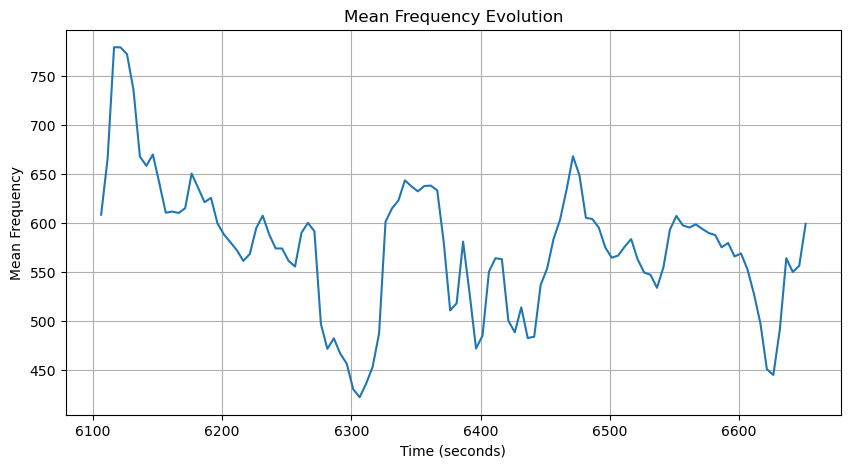

In [28]:
mean_freq = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    mf = np.sum(freqs * spectrum) / np.sum(spectrum)
    mean_freq.append(mf)

mean_freq = np.array(mean_freq)

plt.figure(figsize=(10,5))
plt.plot(time_final, mean_freq)
plt.xlabel("Time (seconds)")
plt.ylabel("Mean Frequency")
plt.title("Mean Frequency Evolution")
plt.grid(True)
plt.show()

freq_features["Mean_Frequency"] = mean_freq

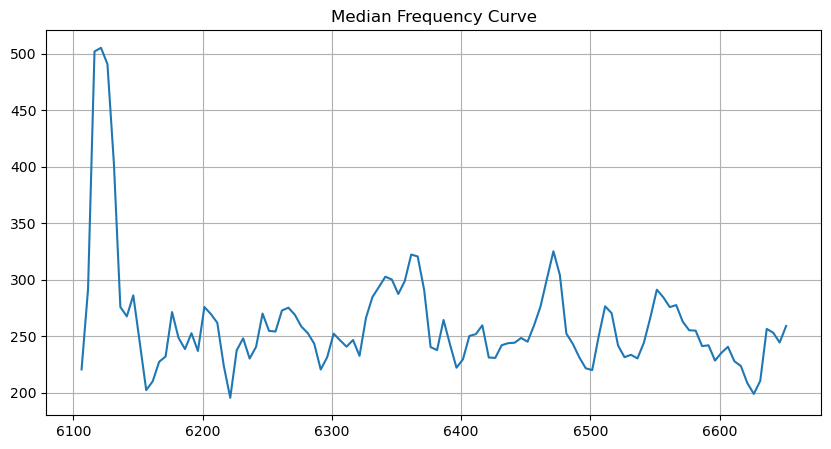

In [29]:
median_freq = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    cumulative = np.cumsum(spectrum)
    median_freq.append(freqs[np.where(cumulative >= cumulative[-1]/2)[0][0]])

median_freq = np.array(median_freq)

plt.figure(figsize=(10,5))
plt.plot(time_final, median_freq)
plt.title("Median Frequency Curve")
plt.grid(True)
plt.show()

freq_features["Median_Frequency"] = median_freq

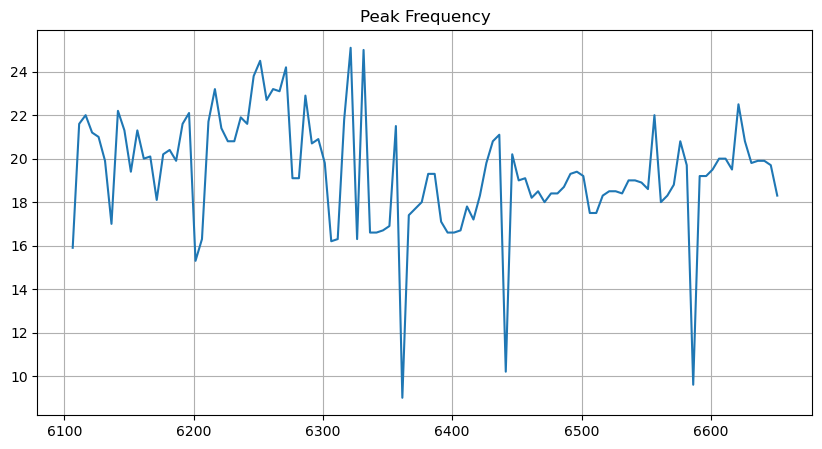

In [30]:
peak_freq = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    peak_freq.append(freqs[np.argmax(spectrum)])

peak_freq = np.array(peak_freq)

plt.figure(figsize=(10,5))
plt.plot(time_final, peak_freq)
plt.title("Peak Frequency")
plt.grid(True)
plt.show()

freq_features["Peak_Frequency"] = peak_freq

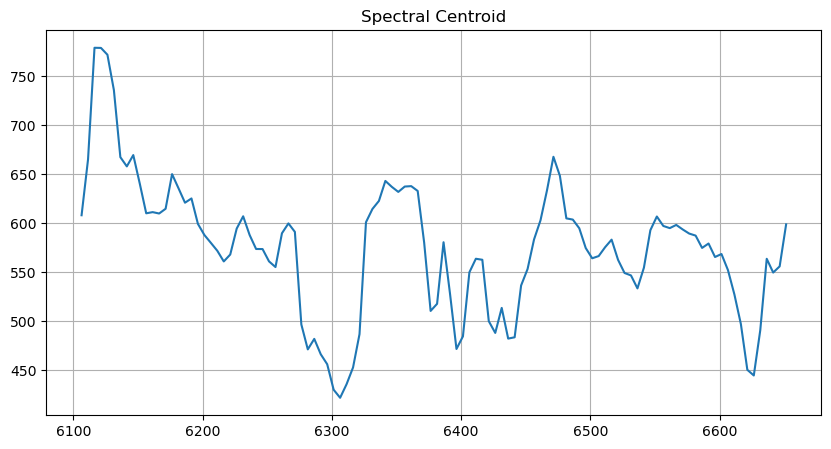

In [31]:
spectral_centroid = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    centroid = np.sum(freqs * spectrum) / np.sum(spectrum)
    spectral_centroid.append(centroid)

spectral_centroid = np.array(spectral_centroid)

plt.figure(figsize=(10,5))
plt.plot(time_final, spectral_centroid)
plt.title("Spectral Centroid")
plt.grid(True)
plt.show()

freq_features["Spectral_Centroid"] = spectral_centroid

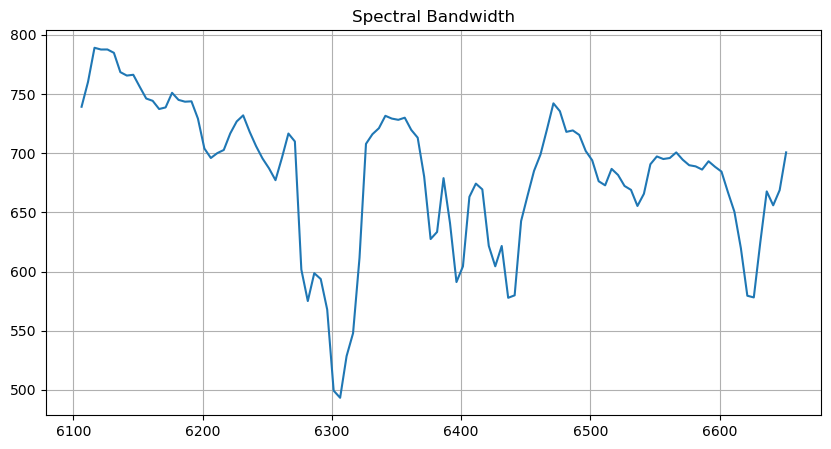

In [32]:
bandwidth = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    centroid = np.sum(freqs * spectrum) / np.sum(spectrum)
    bw = np.sqrt(np.sum(((freqs-centroid)**2)*spectrum)/np.sum(spectrum))
    bandwidth.append(bw)

bandwidth = np.array(bandwidth)

plt.figure(figsize=(10,5))
plt.plot(time_final, bandwidth)
plt.title("Spectral Bandwidth")
plt.grid(True)
plt.show()

freq_features["Spectral_Bandwidth"] = bandwidth

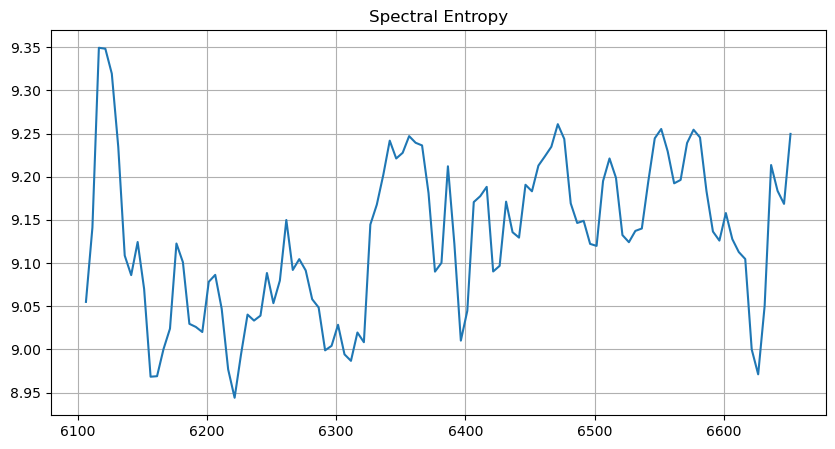

In [33]:
spectral_entropy = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    _, spectrum = get_fft(segment, Fs)

    prob = spectrum / np.sum(spectrum)
    entropy = -np.sum(prob * np.log(prob + 1e-12))
    spectral_entropy.append(entropy)

spectral_entropy = np.array(spectral_entropy)

plt.figure(figsize=(10,5))
plt.plot(time_final, spectral_entropy)
plt.title("Spectral Entropy")
plt.grid(True)
plt.show()

freq_features["Spectral_Entropy"] = spectral_entropy

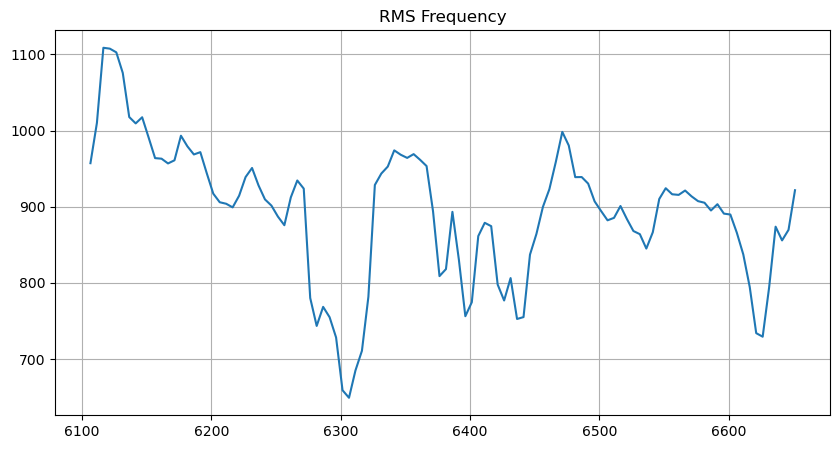

In [34]:
rms_freq = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    rmsf = np.sqrt(np.sum((freqs**2)*spectrum)/np.sum(spectrum))
    rms_freq.append(rmsf)

rms_freq = np.array(rms_freq)

plt.figure(figsize=(10,5))
plt.plot(time_final, rms_freq)
plt.title("RMS Frequency")
plt.grid(True)
plt.show()

freq_features["RMS_Frequency"] = rms_freq

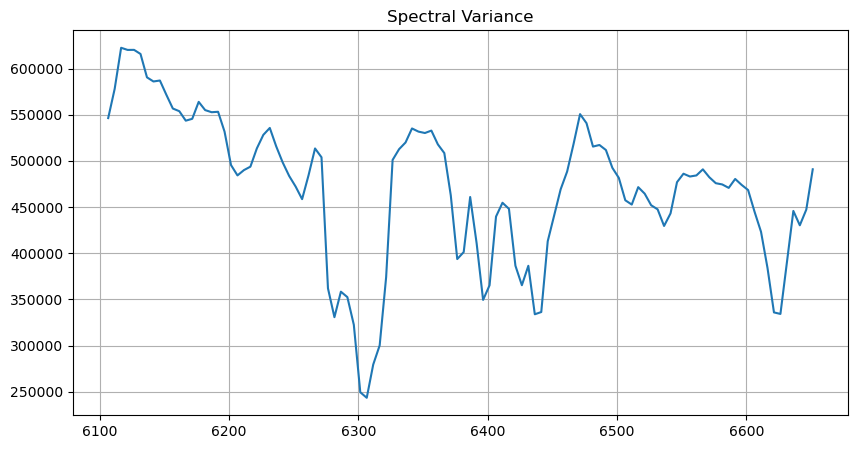

In [35]:
spectral_var = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    centroid = np.sum(freqs*spectrum)/np.sum(spectrum)
    var = np.sum(((freqs-centroid)**2)*spectrum)/np.sum(spectrum)
    spectral_var.append(var)

spectral_var = np.array(spectral_var)

plt.figure(figsize=(10,5))
plt.plot(time_final, spectral_var)
plt.title("Spectral Variance")
plt.grid(True)
plt.show()

freq_features["Spectral_Variance"] = spectral_var

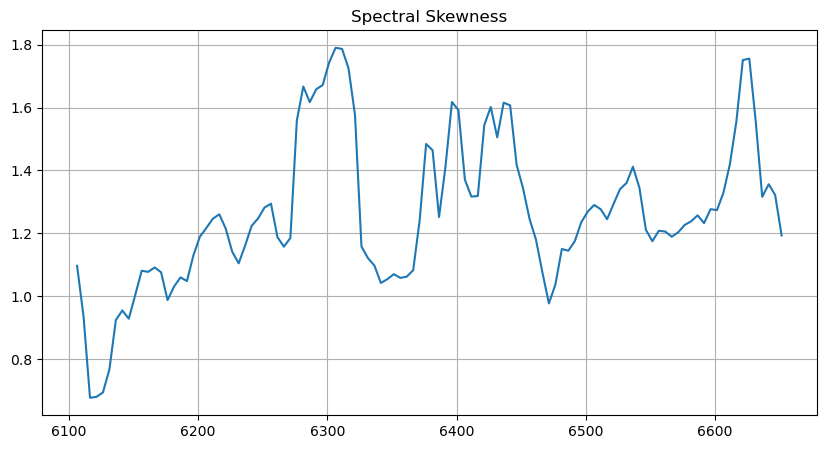

In [36]:
spectral_skew = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    centroid = np.sum(freqs*spectrum)/np.sum(spectrum)
    std = np.sqrt(np.sum(((freqs-centroid)**2)*spectrum)/np.sum(spectrum))

    skew = np.sum(((freqs-centroid)**3)*spectrum)/(std**3*np.sum(spectrum))
    spectral_skew.append(skew)

spectral_skew = np.array(spectral_skew)

plt.figure(figsize=(10,5))
plt.plot(time_final, spectral_skew)
plt.title("Spectral Skewness")
plt.grid(True)
plt.show()

freq_features["Spectral_Skewness"] = spectral_skew

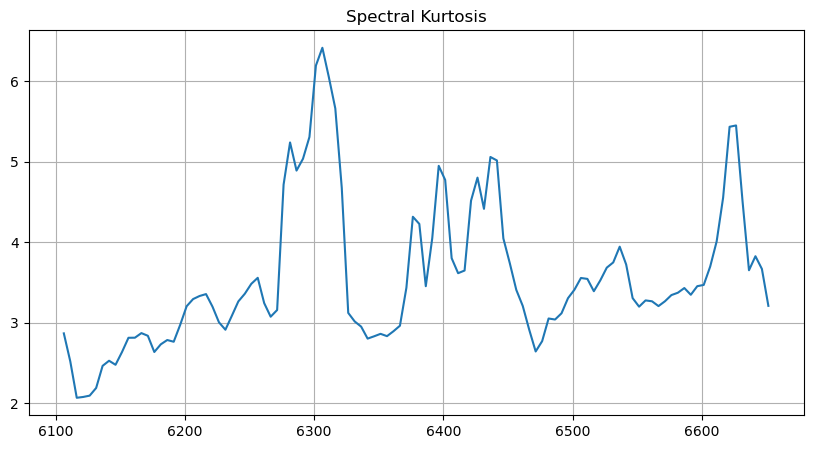

In [37]:
spectral_kurt = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    freqs, spectrum = get_fft(segment, Fs)

    centroid = np.sum(freqs*spectrum)/np.sum(spectrum)
    std = np.sqrt(np.sum(((freqs-centroid)**2)*spectrum)/np.sum(spectrum))

    kurt = np.sum(((freqs-centroid)**4)*spectrum)/(std**4*np.sum(spectrum))
    spectral_kurt.append(kurt)

spectral_kurt = np.array(spectral_kurt)

plt.figure(figsize=(10,5))
plt.plot(time_final, spectral_kurt)
plt.title("Spectral Kurtosis")
plt.grid(True)
plt.show()

freq_features["Spectral_Kurtosis"] = spectral_kurt

In [38]:
freq_df = pd.DataFrame(freq_features)
freq_df["time"] = time_final

In [40]:
final_df = pd.concat([features_df, freq_df.drop(columns=["time"])], axis=1)

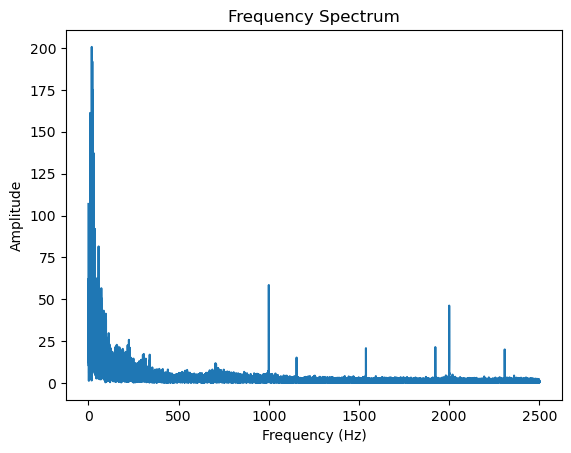

In [41]:
freqs, spectrum = get_fft(segment, Fs)

plt.plot(freqs, spectrum)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Frequency Spectrum")
plt.show()

In [42]:
final_df.head()

,time,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak_to_Peak,Crest_Factor,...,Mean_Frequency,Median_Frequency,Peak_Frequency,Spectral_Centroid,Spectral_Bandwidth,Spectral_Entropy,RMS_Frequency,Spectral_Variance,Spectral_Skewness,Spectral_Kurtosis
0,6106.418785,0.041836,0.001232,0.041818,0.001749,-0.201242,4.666307,0.301106,0.570700,7.197215,...,608.114468,220.802389,15.900172,608.114468,739.203214,9.055054,957.196217,546421.390875,1.096474,2.866322
1,6111.418683,0.035053,0.001335,0.035027,0.001227,-0.234641,9.462654,0.301106,0.570700,8.590124,...,665.054142,291.703157,21.600234,665.054142,760.269731,9.141178,1010.102507,578010.063588,0.935821,2.517750
2,6116.418521,0.024622,0.001837,0.024553,0.000603,0.468614,0.185121,0.129558,0.217097,5.261923,...,778.870226,502.005432,22.000238,778.870226,789.037337,9.349425,1108.701379,622579.919250,0.676662,2.065834
3,6121.418373,0.025593,0.002457,0.025474,0.000649,0.341917,0.142950,0.129558,0.217097,5.062311,...,778.723451,505.305468,21.200229,778.723451,787.567057,9.348334,1107.552294,620261.869942,0.679673,2.076115
4,6126.418210,0.027641,0.001567,0.027596,0.000762,0.172418,0.470335,0.136561,0.266119,4.940582,...,771.767313,490.905312,21.000227,771.767313,787.602248,9.319455,1102.697640,620317.300972,0.693599,2.092488


In [43]:
pip install PyWavelets

Note: you may need to restart the kernel to use updated packages.


In [44]:
import pywt
import numpy as np

tf_features = {}

In [45]:
def wavelet_decompose(signal):
    coeffs = pywt.wavedec(signal, 'db4', level=4)
    return coeffs

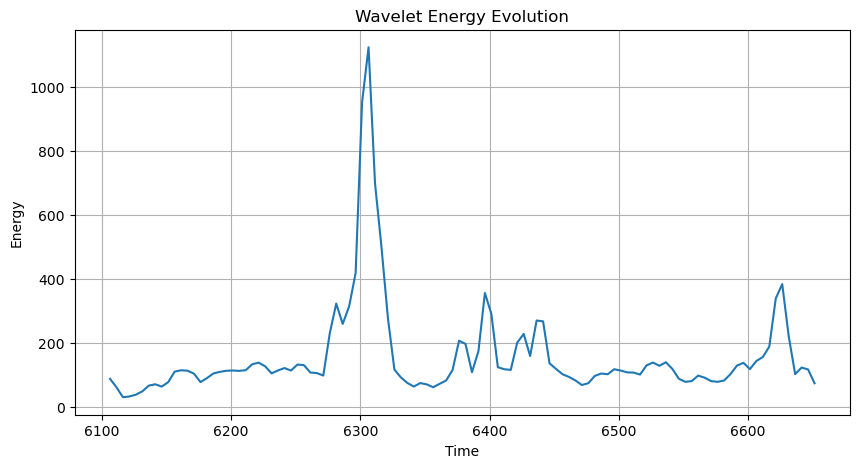

In [46]:
wavelet_energy = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    coeffs = wavelet_decompose(segment)

    energy = sum(np.sum(c**2) for c in coeffs)
    wavelet_energy.append(energy)

wavelet_energy = np.array(wavelet_energy)

plt.figure(figsize=(10,5))
plt.plot(time_final, wavelet_energy)
plt.title("Wavelet Energy Evolution")
plt.xlabel("Time")
plt.ylabel("Energy")
plt.grid(True)
plt.show()

tf_features["Wavelet_Energy"] = wavelet_energy

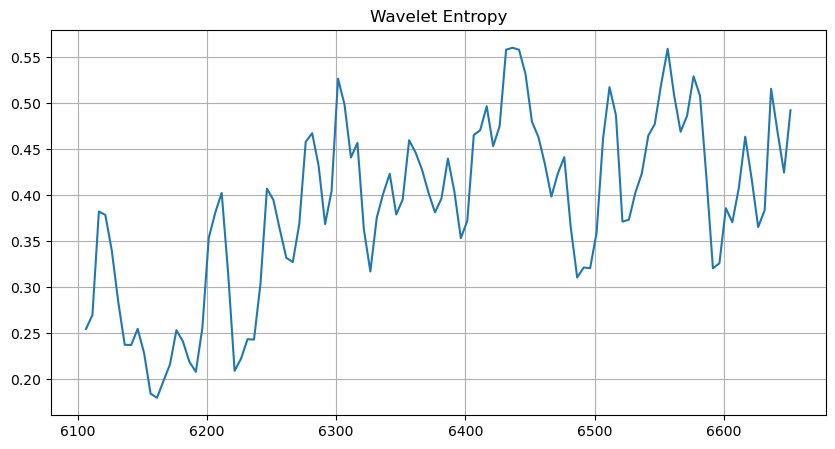

In [47]:
wavelet_entropy = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    coeffs = wavelet_decompose(segment)

    energies = np.array([np.sum(c**2) for c in coeffs])
    prob = energies / np.sum(energies)

    entropy = -np.sum(prob * np.log(prob + 1e-12))
    wavelet_entropy.append(entropy)

wavelet_entropy = np.array(wavelet_entropy)

plt.figure(figsize=(10,5))
plt.plot(time_final, wavelet_entropy)
plt.title("Wavelet Entropy")
plt.grid(True)
plt.show()

tf_features["Wavelet_Entropy"] = wavelet_entropy

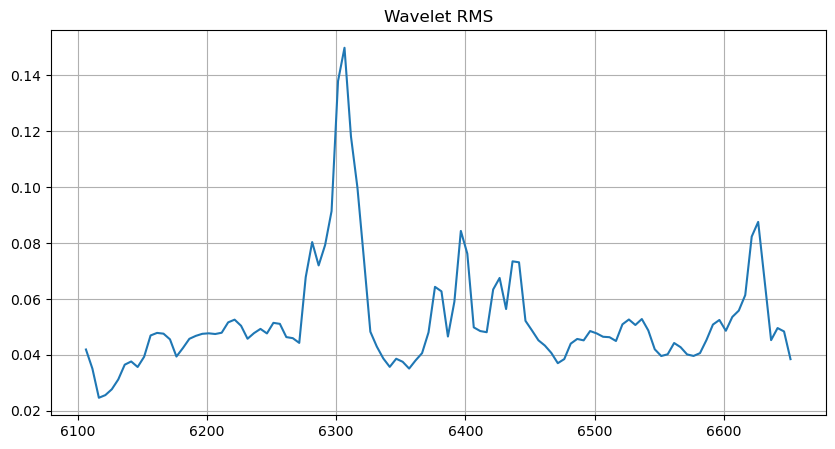

In [48]:
wavelet_rms = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    coeffs = wavelet_decompose(segment)

    combined = np.concatenate(coeffs)
    rms_val = np.sqrt(np.mean(combined**2))
    wavelet_rms.append(rms_val)

wavelet_rms = np.array(wavelet_rms)

plt.figure(figsize=(10,5))
plt.plot(time_final, wavelet_rms)
plt.title("Wavelet RMS")
plt.grid(True)
plt.show()

tf_features["Wavelet_RMS"] = wavelet_rms

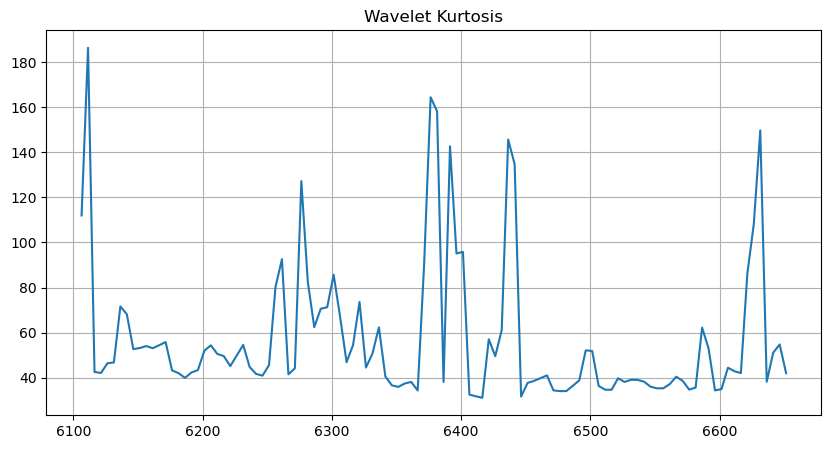

In [49]:
from scipy.stats import kurtosis

wavelet_kurt = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    coeffs = wavelet_decompose(segment)

    combined = np.concatenate(coeffs)
    wavelet_kurt.append(kurtosis(combined))

wavelet_kurt = np.array(wavelet_kurt)

plt.figure(figsize=(10,5))
plt.plot(time_final, wavelet_kurt)
plt.title("Wavelet Kurtosis")
plt.grid(True)
plt.show()

tf_features["Wavelet_Kurtosis"] = wavelet_kurt

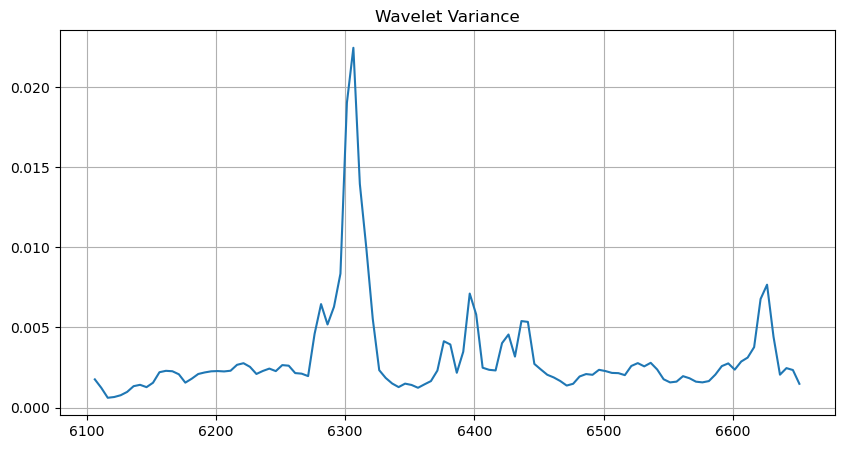

In [50]:
wavelet_var = []

for i in range(0, len(vibration)-window_size, step):

    segment = vibration[i:i+window_size]
    coeffs = wavelet_decompose(segment)

    combined = np.concatenate(coeffs)
    wavelet_var.append(np.var(combined))

wavelet_var = np.array(wavelet_var)

plt.figure(figsize=(10,5))
plt.plot(time_final, wavelet_var)
plt.title("Wavelet Variance")
plt.grid(True)
plt.show()

tf_features["Wavelet_Variance"] = wavelet_var

In [51]:
tf_df = pd.DataFrame(tf_features)
tf_df["time"] = time_final

In [53]:
final_all_df = pd.concat([
    final_df.drop(columns=["time"]),
    tf_df
], axis=1)

In [54]:
final_all_df.head()

,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak_to_Peak,Crest_Factor,MAV,...,RMS_Frequency,Spectral_Variance,Spectral_Skewness,Spectral_Kurtosis,Wavelet_Energy,Wavelet_Entropy,Wavelet_RMS,Wavelet_Kurtosis,Wavelet_Variance,time
0,0.041836,0.001232,0.041818,0.001749,-0.201242,4.666307,0.301106,0.570700,7.197215,0.030439,...,957.196217,546421.390875,1.096474,2.866322,87.894404,0.254780,0.041916,112.009533,0.001757,6106.418785
1,0.035053,0.001335,0.035027,0.001227,-0.234641,9.462654,0.301106,0.570700,8.590124,0.024624,...,1010.102507,578010.063588,0.935821,2.517750,61.478069,0.269885,0.035056,186.533488,0.001229,6111.418683
2,0.024622,0.001837,0.024553,0.000603,0.468614,0.185121,0.129558,0.217097,5.261923,0.020003,...,1108.701379,622579.919250,0.676662,2.065834,30.381020,0.382244,0.024643,42.485825,0.000607,6116.418521
3,0.025593,0.002457,0.025474,0.000649,0.341917,0.142950,0.129558,0.217097,5.062311,0.020879,...,1107.552294,620261.869942,0.679673,2.076115,32.772840,0.378525,0.025595,42.002905,0.000655,6121.418373
4,0.027641,0.001567,0.027596,0.000762,0.172418,0.470335,0.136561,0.266119,4.940582,0.022435,...,1102.697640,620317.300972,0.693599,2.092488,38.337264,0.339811,0.027683,46.339378,0.000766,6126.418210


In [56]:
final_all_df.columns

Index(['RMS', 'Mean', 'Std', 'Variance', 'Skewness', 'Kurtosis', 'Peak',
       'Peak_to_Peak', 'Crest_Factor', 'MAV', 'Shape_Factor',
       'Clearance_Factor', 'Mean_Frequency', 'Median_Frequency',
       'Peak_Frequency', 'Spectral_Centroid', 'Spectral_Bandwidth',
       'Spectral_Entropy', 'RMS_Frequency', 'Spectral_Variance',
       'Spectral_Skewness', 'Spectral_Kurtosis', 'Wavelet_Energy',
       'Wavelet_Entropy', 'Wavelet_RMS', 'Wavelet_Kurtosis',
       'Wavelet_Variance', 'time'],
      dtype='object')

In [76]:
from sklearn.preprocessing import MinMaxScaler

time_col = final_all_df["time"]
X = final_all_df.drop(columns=["time"])

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled["time"] = time_col

X_scaled.head()

,RMS,Mean,Std,Variance,Skewness,Kurtosis,Peak,Peak_to_Peak,Crest_Factor,MAV,...,RMS_Frequency,Spectral_Variance,Spectral_Skewness,Spectral_Kurtosis,Wavelet_Energy,Wavelet_Entropy,Wavelet_RMS,Wavelet_Kurtosis,Wavelet_Variance,time
0,0.137450,0.327027,0.137781,0.052431,0.268656,0.509037,0.153355,0.171469,0.514298,0.115408,...,0.670259,0.799145,0.377024,0.184028,0.052614,0.196540,0.137942,0.520864,0.052620,6106.418785
1,0.083285,0.347732,0.083585,0.028553,0.232191,1.000000,0.153355,0.171469,0.703979,0.051106,...,0.785406,0.882454,0.232745,0.103893,0.028448,0.236307,0.083155,1.000000,0.028452,6111.418683
2,0.000000,0.448388,0.000000,0.000000,1.000000,0.050334,0.000000,0.000000,0.250756,0.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.532111,0.000000,0.073877,0.000000,6116.418521
3,0.007752,0.572919,0.007352,0.002109,0.861673,0.046017,0.000000,0.000000,0.223574,0.009684,...,0.997499,0.993887,0.002704,0.002364,0.002188,0.522322,0.007600,0.070772,0.002180,6121.418373
4,0.024104,0.394277,0.024284,0.007261,0.676615,0.079529,0.006260,0.023772,0.206997,0.026890,...,0.986933,0.994033,0.015211,0.006128,0.007278,0.420400,0.024273,0.098652,0.007281,6126.418210


In [77]:
from sklearn.decomposition import PCA

X_only = X_scaled.drop(columns=["time"])

pca = PCA()
pca_data = pca.fit_transform(X_only)

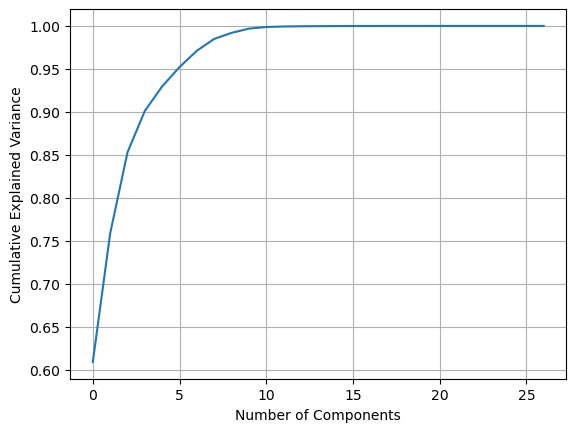

In [78]:
import matplotlib.pyplot as plt

plt.plot(pca.explained_variance_ratio_.cumsum())
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid(True)
plt.show()

In [79]:
from sklearn.decomposition import PCA

pca = PCA(n_components=5)
pca_data = pca.fit_transform(X_only)

In [80]:
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2", "PC3", "PC4","PC5"]
)

pca_df["time"] = X_scaled["time"]
pca_df.head()

,PC1,PC2,PC3,PC4,PC5,time
0,-0.036224,0.838091,-0.138015,-0.097285,-0.294152,6106.418785
1,-0.015820,1.560060,0.235129,-0.015720,-0.010178,6111.418683
2,-1.430352,0.354922,0.563912,0.714047,0.435579,6116.418521
3,-1.423557,0.323131,0.549770,0.697442,0.348685,6121.418373
4,-1.348607,0.392898,0.422675,0.668558,0.172622,6126.418210


In [92]:
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1} explains {var*100:.2f}% variance")

PC1 explains 60.95% variance
PC2 explains 14.93% variance
PC3 explains 9.43% variance
PC4 explains 4.81% variance
PC5 explains 2.85% variance


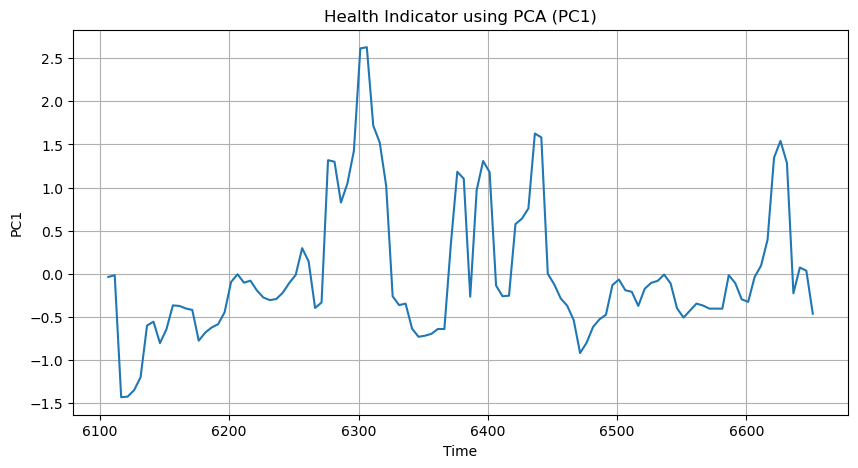

In [81]:
plt.figure(figsize=(10,5))
plt.plot(pca_df["time"], pca_df["PC1"])
plt.xlabel("Time")
plt.ylabel("PC1")
plt.title("Health Indicator using PCA (PC1)")
plt.grid(True)
plt.show()

In [82]:
corr_scores = X_scaled.drop(columns=["time"]).corrwith(X_scaled["time"])
corr_scores = corr_scores.abs().sort_values(ascending=False)

print(corr_scores)

Wavelet_Entropy       0.620201
Spectral_Skewness     0.401316
Spectral_Variance     0.399589
RMS_Frequency         0.373755
Spectral_Centroid     0.370378
Mean_Frequency        0.370378
Spectral_Bandwidth    0.365344
Spectral_Entropy      0.335754
Spectral_Kurtosis     0.307542
Median_Frequency      0.292664
Peak_Frequency        0.238039
Shape_Factor          0.164587
Wavelet_Kurtosis      0.137426
Mean                  0.126178
MAV                   0.107287
Skewness              0.094727
Clearance_Factor      0.094538
Kurtosis              0.076449
Wavelet_RMS           0.075544
RMS                   0.075519
Std                   0.075396
Crest_Factor          0.074369
Wavelet_Energy        0.010542
Wavelet_Variance      0.010536
Variance              0.010416
Peak_to_Peak          0.009780
Peak                  0.006412
dtype: float64


In [83]:
selected_features = corr_scores.index[:5]
print(selected_features)

Index(['Wavelet_Entropy', 'Spectral_Skewness', 'Spectral_Variance',
       'RMS_Frequency', 'Spectral_Centroid'],
      dtype='object')


In [84]:
HI = X_scaled[selected_features].mean(axis=1)
X_scaled["HI"] = HI

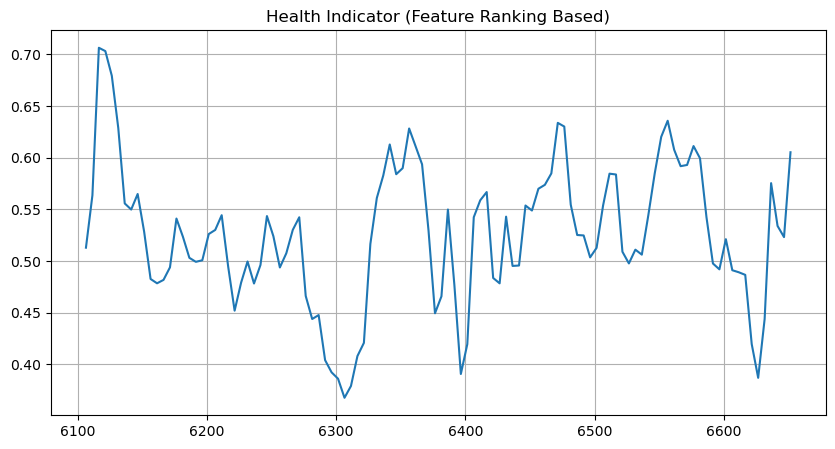

In [85]:
plt.figure(figsize=(10,5))
plt.plot(X_scaled["time"], X_scaled["HI"])
plt.title("Health Indicator (Feature Ranking Based)")
plt.grid(True)
plt.show()

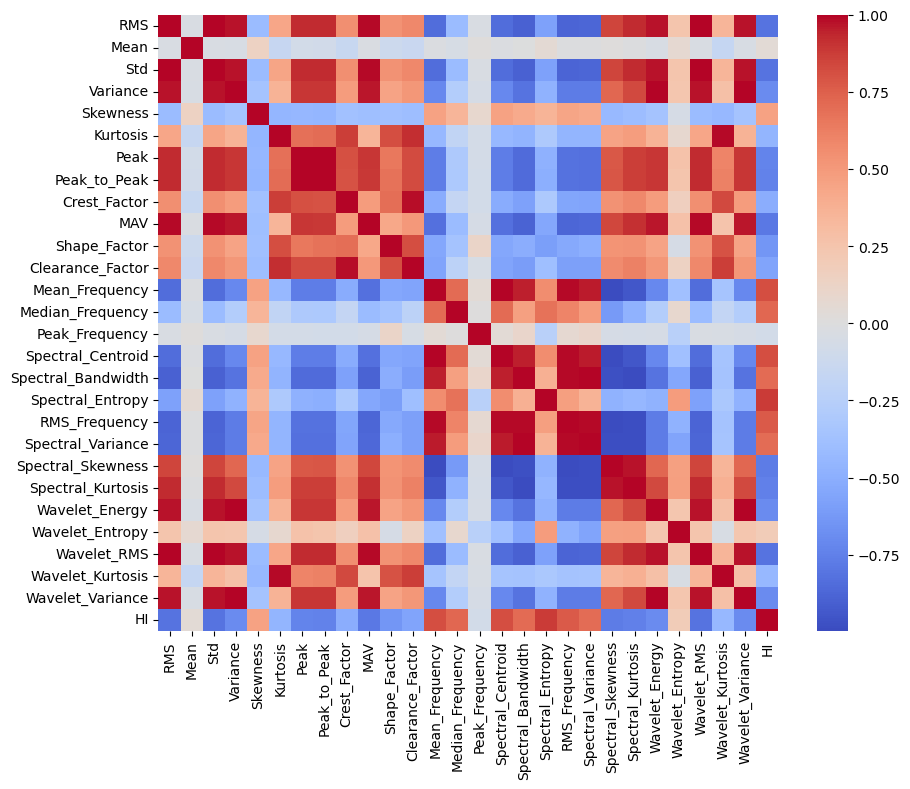

In [86]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(X_scaled.drop(columns=["time"]).corr(), cmap="coolwarm")
plt.show()